# IMPORTS DE LIBRERIAS

In [81]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

Importamos las librerias correspondientes para trabajar la base

## APERTURA Y ANALISIS DE LA BASE

In [82]:
# Si está en la misma carpeta que la notebook:
df = pd.read_csv('CKD_NHANES_2021_2023.csv')
df

,participant_id,age,gender,ethnicity,education_level,poverty_income_ratio,bmi,weight_kg,height_cm,bp_systolic,...,urine_albumin,albumin_creatinine_ratio,diabetes_diagnosed,insulin_use,diabetes_pills,ever_smoked,current_smoker,egfr,ckd_stage,ckd_present
0,130378.0,43.0,Male,Non-Hispanic Asian,5.0,5.00,27.0,86.9,179.5,135.0,...,23.12,17.00,2.0,NaN,NaN,1.0,3.0,112.61,No CKD,0
1,130379.0,66.0,Male,Non-Hispanic White,5.0,5.00,33.5,101.8,174.2,121.0,...,4.25,6.64,2.0,NaN,NaN,1.0,3.0,97.98,No CKD,0
2,130380.0,44.0,Female,Other Hispanic,3.0,1.41,29.7,69.4,152.9,111.0,...,12.43,7.92,1.0,2.0,1.0,2.0,NaN,111.69,No CKD,0
3,130381.0,5.0,Female,Other/Multiracial,NaN,1.53,23.8,34.3,120.1,NaN,...,16.12,7.75,2.0,NaN,NaN,NaN,NaN,NaN,Unknown,1
4,130382.0,2.0,Male,Non-Hispanic White,NaN,3.60,NaN,13.6,NaN,NaN,...,NaN,NaN,2.0,NaN,NaN,NaN,NaN,NaN,Unknown,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11928,142306.0,9.0,Male,Other Hispanic,NaN,2.01,15.4,25.3,128.0,NaN,...,NaN,NaN,2.0,NaN,NaN,NaN,NaN,NaN,Unknown,1
11929,142307.0,49.0,Female,Non-Hispanic Black,5.0,NaN,NaN,NaN,143.8,127.0,...,6.31,6.78,1.0,2.0,1.0,1.0,3.0,91.64,No CKD,0
11930,142308.0,50.0,Male,Other Hispanic,4.0,1.95,26.4,79.3,173.3,106.0,...,6.98,4.03,2.0,NaN,NaN,2.0,NaN,NaN,Unknown,1
11931,142309.0,40.0,Male,Other Hispanic,4.0,3.11,25.5,81.9,179.1,127.0,...,9.27,3.65,2.0,NaN,NaN,2.0,NaN,92.03,No CKD,0


In [83]:
#Analizamos el dataset, imprimimos su info
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11933 entries, 0 to 11932
Data columns (total 29 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   participant_id            11933 non-null  float64
 1   age                       11933 non-null  float64
 2   gender                    11933 non-null  str    
 3   ethnicity                 11933 non-null  str    
 4   education_level           7794 non-null   float64
 5   poverty_income_ratio      9892 non-null   float64
 6   bmi                       8471 non-null   float64
 7   weight_kg                 8754 non-null   float64
 8   height_cm                 8499 non-null   float64
 9   bp_systolic               7517 non-null   float64
 10  bp_diastolic              7517 non-null   float64
 11  serum_creatinine          6326 non-null   float64
 12  blood_urea_nitrogen       6326 non-null   float64
 13  albumin_serum             6366 non-null   float64
 14  phosphorus       

Aca ya imprimimos las 29 columnas del dataset, donde podemos ver tambien el tipo de cada columna.
Y tambien hacemos un describe() para obtener informacion de cada columna.

In [84]:
df.describe()

,participant_id,age,education_level,poverty_income_ratio,bmi,weight_kg,height_cm,bp_systolic,bp_diastolic,serum_creatinine,...,urine_creatinine,urine_albumin,albumin_creatinine_ratio,diabetes_diagnosed,insulin_use,diabetes_pills,ever_smoked,current_smoker,egfr,ckd_present
count,11933.000000,1.193300e+04,7794.000000,9.892000e+03,8471.000000,8754.000000,8499.000000,7517.000000,7517.000000,6326.000000,...,8154.000000,8153.000000,8153.000000,11740.000000,1081.000000,2281.000000,8135.000000,3243.000000,6326.000000,11933.000000
mean,136344.000000,3.831786e+01,3.804978,2.708174e+00,27.246665,70.549037,159.664549,119.288546,72.748038,0.872828,...,133.258646,35.567928,33.355533,1.934497,1.681776,1.633494,1.611678,2.339500,96.599750,0.698986
std,3444.904716,2.560199e+01,1.153750,1.670119e+00,8.137781,30.389021,19.864943,18.561052,11.895572,0.385498,...,90.676053,175.582217,251.094041,0.358726,0.466002,0.635776,0.558182,0.900889,24.633731,0.458718
min,130378.000000,5.397605e-79,1.000000,5.397605e-79,11.100000,2.700000,79.100000,61.000000,33.000000,0.330000,...,4.000000,0.210000,0.080000,1.000000,1.000000,1.000000,1.000000,1.000000,3.510000,0.000000
25%,133361.000000,1.300000e+01,3.000000,1.180000e+00,21.600000,54.200000,154.400000,106.000000,64.000000,0.700000,...,65.000000,5.770000,5.420000,2.000000,1.000000,1.000000,1.000000,1.000000,80.502500,0.000000
50%,136344.000000,3.700000e+01,4.000000,2.500000e+00,26.400000,71.700000,163.600000,117.000000,72.000000,0.830000,...,117.000000,9.620000,8.270000,2.000000,2.000000,2.000000,2.000000,3.000000,97.030000,1.000000
75%,139327.000000,6.200000e+01,5.000000,4.500000e+00,31.700000,89.100000,172.100000,130.000000,80.000000,0.980000,...,181.000000,17.830000,15.330000,2.000000,2.000000,2.000000,2.000000,3.000000,112.660000,1.000000
max,142310.000000,8.000000e+01,9.000000,5.000000e+00,74.800000,248.200000,200.700000,232.000000,142.000000,15.170000,...,873.000000,7942.470000,14708.280000,9.000000,2.000000,9.000000,9.000000,3.000000,178.430000,1.000000


# ANALISIS EXPLORATORIO DE DATOS

Ahora pasamos a contar la cantidad de filas repetidas que hay en el dataset

In [85]:
df.duplicated().sum()

np.int64(0)

Vemos que no hay ninguna fila repetida, debido a que participant_id es un valor unico de cada persona.
Ahora vamos a contar cuantos nulos hay por cada columna, y agregamos una columna con el porcentaje de estos.

In [86]:
# Conteo y porcentaje de valores faltantes por variable
nulos = pd.DataFrame({
    'nulos': df.isnull().sum(),
    'porcentaje': (df.isnull().mean() * 100).round(2),
}).sort_values(by='porcentaje', ascending=False)

print(nulos)

                          nulos  porcentaje
insulin_use               10852       90.94
diabetes_pills             9652       80.88
current_smoker             8690       72.82
phosphorus                 5611       47.02
bicarbonate                5608       47.00
blood_urea_nitrogen        5607       46.99
serum_creatinine           5607       46.99
egfr                       5607       46.99
uric_acid                  5604       46.96
calcium                    5571       46.69
albumin_serum              5567       46.65
bp_diastolic               4416       37.01
bp_systolic                4416       37.01
education_level            4139       34.69
ever_smoked                3798       31.83
urine_albumin              3780       31.68
albumin_creatinine_ratio   3780       31.68
urine_creatinine           3779       31.67
bmi                        3462       29.01
height_cm                  3434       28.78
weight_kg                  3179       26.64
poverty_income_ratio       2041 

## ANALISIS DE LOS NULOS

Podemos ver que la columna con mas nulos es insuline_use, y esto se debe a que solo respondieron la pregunta sobre el uso de insulina, los pacientes a los que un profesional les diagnosticó diabetes. 1 es que usa insulina, 2 es que no.

Con las columnas relacionadas a los analisis de sangre lo que pasó es que se analizó a personas mayores de 12 años, aunque tambien hay algunos analisis faltantes más de personas que no fueron al examen(faltan todos sus datos de sangre). Y hay otros(62 personas) que tienen solo algunos datos de la sangre

Lo mismo pasó con la presion arterial, bp_systolic y bp_diastolic solo se midieron paraa personas mayores de 8 años(y tambien hay algunos que no asistieron, pero siempre faltan ambas columnas). 

Con las columnas de orina (urine_albumin, urine_creatinine, albumin_creatinine_ratio) tambien faltan muestras, faltan juntas. 

Para las columnas education_level y ever_smoked, solo vamos a filtrar para quedarnos con los adultos mayores a 20 años, luego de eso tendremos unos 26 y 29 nulos respectivamente, lo cual representa menos del 0,5% de los datos, por lo que podemos descartar esas filas cuando usemos la columna.

Con respecto a los nulos en las medidas corporales(bmi, height_cm, weight_kg), lo que intentamos hacer es, si tenemos 2 de las 3 medidas, calular la faltante, ya que bmi es un calculo entre height_cm y weight_kg. Pero, no hay ningun caso en el dataset donde tengamos 2 medidas y falte 1.

falta decidir que hacer con poverty_income_ratio y con ckd_stage(y ckd_present) por el tema del unknown

Tambien, pasamos a NaN a los valores 7 y 9 de las columnas indicadas ya que estos codigos representan "Se negó a responder / no sabe"

In [87]:
cols_cuestionario = [c for c in ['diabetes_diagnosed', 'ever_smoked', 'education_level', 'diabetes_pills'] if c in df.columns]

for col in cols_cuestionario:
    # 7 y 9 son valores no informativos en NHANES -> los pasamos a NaN
    df[col] = df[col].replace({7: np.nan, 9: np.nan})

In [88]:
#pasamos a 0 las edades que son numeros cercanos a 0
df.loc[df['age'] < 1e-10, 'age'] = 0
print(df.iloc[129])

participant_id                        130507.0
age                                        1.0
gender                                  Female
ethnicity                   Non-Hispanic White
education_level                            NaN
poverty_income_ratio                       1.7
bmi                                        NaN
weight_kg                                 12.1
height_cm                                  NaN
bp_systolic                                NaN
bp_diastolic                               NaN
serum_creatinine                           NaN
blood_urea_nitrogen                        NaN
albumin_serum                              NaN
phosphorus                                 NaN
bicarbonate                                NaN
calcium                                    NaN
uric_acid                                  NaN
urine_creatinine                           NaN
urine_albumin                              NaN
albumin_creatinine_ratio                   NaN
diabetes_diag

In [89]:
#filtramos por edad y vemos la cantidad de nulos de las dos columnas mencionadas antes
#mayores de 12(analisis de sangre)
sangre = ["phosphorus", "bicarbonate", "blood_urea_nitrogen", "serum_creatinine",
          "egfr", "uric_acid", "calcium", "albumin_serum"]

df_sangre = df[df['age'] >= 12]
faltantes = df_sangre[sangre].isna().sum(axis=1)      
# cuántos de los 8 le faltan a cada persona

print("Personas de mayores de 12:", len(df_sangre))
print(faltantes.value_counts().sort_index())
print("Les faltan los 8:", (faltantes == 8).sum())
print("Les faltan algunos, pero no todos:", ((faltantes > 0) & (faltantes < 8)).sum())

Personas de mayores de 12: 9388
0    6304
1      19
2       2
3       2
4       2
5      13
6      24
8    3022
Name: count, dtype: int64
Les faltan los 8: 3022
Les faltan algunos, pero no todos: 62


In [90]:
presion = ["bp_systolic", "bp_diastolic"]
df_presion = df[df['age'] >= 8]
print(df_presion['bp_systolic'].isnull().sum())
print(df_presion['bp_diastolic'].isnull().sum())
faltantes_presion = df_presion[presion].isna().sum(axis=1)

print("Personas de mayores de 8:", len(df_presion))
print("Les faltan los 2:", (faltantes_presion == 2).sum())
print("Les faltan algunos, pero no todos:", ((faltantes_presion > 0) & (faltantes_presion < 2)).sum())

2770
2770
Personas de mayores de 8: 10287
Les faltan los 2: 2770
Les faltan algunos, pero no todos: 0


In [91]:
#mayores de 20
df_filtrado_mayores = df[df['age'] >= 20]
print(df_filtrado_mayores['education_level'].isnull().sum())
print(df_filtrado_mayores['ever_smoked'].isnull().sum())

26
29


In [92]:
#notna() detecta los válidos o existentes, devuelve True para los datos presentes y False para los valores nulos
#habiamos intentado calcular los datos faltantes a partir de 2 valores, pero no hay ninguna fila que tenga 2 valores como para calcular el otro
medidas = ["bmi", "weight_kg", "height_cm"]
cantidad = df[medidas].notna().sum(axis=1)

print(cantidad.value_counts().sort_index())
print("Filas con  2 medidas:", (cantidad == 2).sum())

0    3151
1     311
3    8471
Name: count, dtype: int64
Filas con  2 medidas: 0


In [93]:
# hay casos que tienen eGFR mayor a 90 pero tienen el ACR en nulo, y en ckd_stage tienen como valor NO_CKD(esto segun la informacion
# que tenemos es cuando el eGFR es mayor o igual a 90 y el ACR es menor a 30). Al no tener valor de ACR este dato es inconsistente, y como
# tenemos 70 casos de este tipo(que tienen eGFR mayor o igual a 90 y ACR menor a 30) lo cual es un 1,76% de los 3974 datos, 
# podemos descartar estas filas.

inconsistencia_ckd = df['albumin_creatinine_ratio'].isna() & (df['egfr'] >= 90)

# Filtramos el DataFrame conservando todo lo opuesto (el símbolo ~ niega la condición)
df_limpio = df[~inconsistencia_ckd].copy()

In [94]:
filtro_unknown = df['ckd_stage'] == 'Unknown'

# Ponemos nulo en ckd_stage y ckd_present para esas filas donde es unknown
df.loc[filtro_unknown, 'ckd_present'] = np.nan
df.loc[filtro_unknown, 'ckd_stage'] = np.nan
df

,participant_id,age,gender,ethnicity,education_level,poverty_income_ratio,bmi,weight_kg,height_cm,bp_systolic,...,urine_albumin,albumin_creatinine_ratio,diabetes_diagnosed,insulin_use,diabetes_pills,ever_smoked,current_smoker,egfr,ckd_stage,ckd_present
0,130378.0,43.0,Male,Non-Hispanic Asian,5.0,5.00,27.0,86.9,179.5,135.0,...,23.12,17.00,2.0,NaN,NaN,1.0,3.0,112.61,No CKD,0.0
1,130379.0,66.0,Male,Non-Hispanic White,5.0,5.00,33.5,101.8,174.2,121.0,...,4.25,6.64,2.0,NaN,NaN,1.0,3.0,97.98,No CKD,0.0
2,130380.0,44.0,Female,Other Hispanic,3.0,1.41,29.7,69.4,152.9,111.0,...,12.43,7.92,1.0,2.0,1.0,2.0,NaN,111.69,No CKD,0.0
3,130381.0,5.0,Female,Other/Multiracial,NaN,1.53,23.8,34.3,120.1,NaN,...,16.12,7.75,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,130382.0,2.0,Male,Non-Hispanic White,NaN,3.60,NaN,13.6,NaN,NaN,...,NaN,NaN,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11928,142306.0,9.0,Male,Other Hispanic,NaN,2.01,15.4,25.3,128.0,NaN,...,NaN,NaN,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
11929,142307.0,49.0,Female,Non-Hispanic Black,5.0,NaN,NaN,NaN,143.8,127.0,...,6.31,6.78,1.0,2.0,1.0,1.0,3.0,91.64,No CKD,0.0
11930,142308.0,50.0,Male,Other Hispanic,4.0,1.95,26.4,79.3,173.3,106.0,...,6.98,4.03,2.0,NaN,NaN,2.0,NaN,NaN,NaN,NaN
11931,142309.0,40.0,Male,Other Hispanic,4.0,3.11,25.5,81.9,179.1,127.0,...,9.27,3.65,2.0,NaN,NaN,2.0,NaN,92.03,No CKD,0.0


# Hipótesis y resolución

### UNIVARIADAS

### Hipotesis univariada 1: “Predomina el sobrepeso en la muestra”

En la metadata se menciona el **exceso de peso** entre los factores relacionados con el **deterioro renal**.
Que **“predomine”** lo tomamos como que las categorías **sobrepeso** y **obesidad** son más frecuentes y significativamentes mayores que las otras.

En caso de probarse, se podrián tomar **medidas para concientizar** sobre el exceso de peso y sus consecuencias. Y aunque el analisis es sobre adultos, las medidas pueden llevarse a todas las edades, para que los mas jovenes no lleguen a una situacion de exceso de peso que **afecte su salud** a largo plazo.

In [95]:
# para este analisis solo vamos a usar a los adultos del dataset
# filtramos solo la población adulta (>= 18 años) para usar los cortes estándar 
# de Indice de Masa Corporal (BMI como aparece en nuestro dataset)
df_adultos = df[df['age'] >= 18].copy()

# Ver cuántos adultos no tenían registro de bmi
nulos_bmi = df_adultos['bmi'].isna().sum()
print(f"Adultos excluidos por falta de datos de bmi: {nulos_bmi}")


# Definimos los límites de las categorías de la OMS para el bmi
limites = [0, 18.5, 25, 30, float('inf')]
labels = ['Bajo peso', 'Normopeso', 'Sobrepeso', 'Obesidad']

# en df_adultos creamos una nueva columna categórica con el estado nutricional
df_adultos['estado_nutricional'] = pd.cut(df_adultos['bmi'], bins=limites, labels=labels, right=False)

# Calculamos frecuencias y porcentajes
conteo_imc = df_adultos['estado_nutricional'].value_counts()
porcentajes_imc = df_adultos['estado_nutricional'].value_counts(normalize=True) * 100

print("Frecuencias")
print(conteo_imc)
print("\n Porcentajes %")
print(porcentajes_imc.round(2))


Adultos excluidos por falta de datos de bmi: 1918
Frecuencias
estado_nutricional
Obesidad     2524
Sobrepeso    1961
Normopeso    1642
Bajo peso     108
Name: count, dtype: int64

 Porcentajes %
estado_nutricional
Obesidad     40.48
Sobrepeso    31.45
Normopeso    26.34
Bajo peso     1.73
Name: proportion, dtype: float64


Ahora podemos generar los **graficos** para hacer la comparación

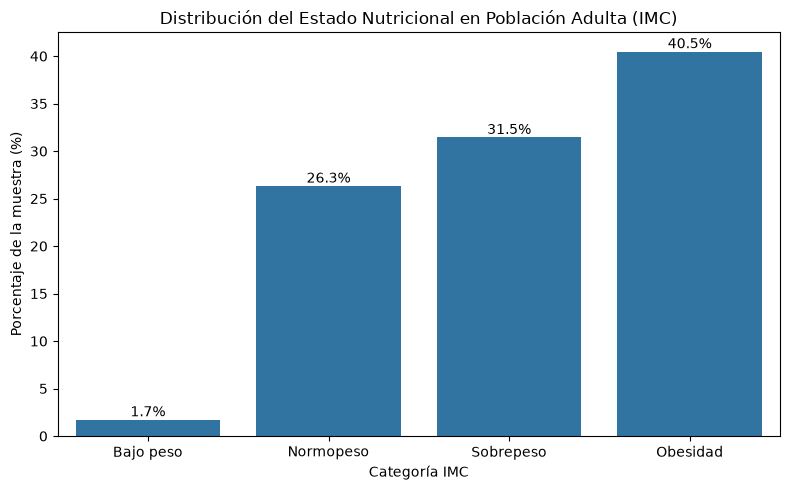

In [96]:
# gráfico de distribución
plt.figure(figsize=(8, 5))
ax = sns.barplot(x=porcentajes_imc.index, y=porcentajes_imc.values)
plt.title('Distribución del Estado Nutricional en Población Adulta (IMC)')
plt.xlabel('Categoría IMC')
plt.ylabel('Porcentaje de la muestra (%)')

# Añade los valores numéricos arriba de las barras
for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}%", 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='center', xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()

### Resultados
Mediante el grafico podemos concluir que **nuestra hipotesis se cumple**, ya que hay un **40,5%** de personas con **obesidad** y un **31,5%** de personas con **sobrepeso**. Ambas categorias se estudian como **"Exceso de Peso"** el cual es un factor relacionado con el deterioro renal.

#### Aclaraciones: 
cuando bmi es NaN, la nueva columna tambien tiene NaN. 
Ademas value_counts() ignora y descarta automáticamente todos los valores nulos.
Por esto mismo, aclaramos cuantos adultos fueron excluidos por no tener ibm.

### BIVARIADAS

### HIPOTESIS BIVARIADA 1: "La proporción de personas con diagnóstico positivo de diabetes (diabetes_diagnosed) es significativamente mayor en los estratos de menor nivel de ingresos (medido a través del poverty_income_ratio)."

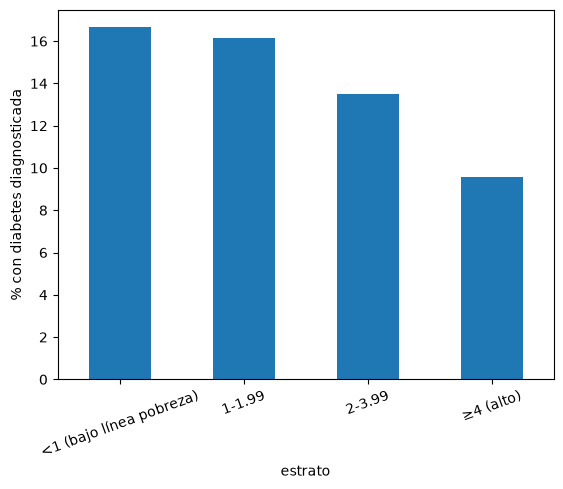

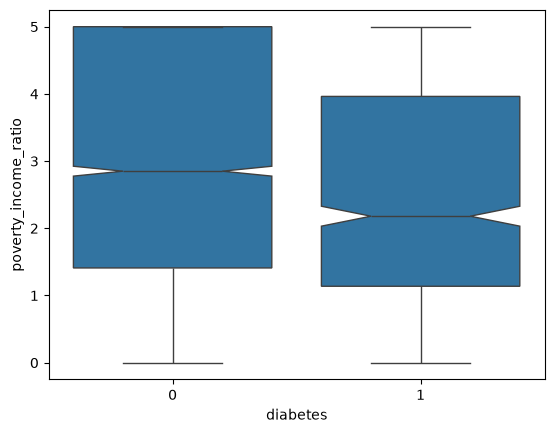

In [97]:
h_b1 = df[df["age"] >= 18].copy()
h_b1["diabetes"] = (h_b1["diabetes_diagnosed"] == 1).astype(int)
h_b1["estrato"] = pd.cut(h_b1["poverty_income_ratio"], [0, 1, 2, 4, 5.01], right=False,
                       labels=["<1 (bajo línea pobreza)", "1-1.99", "2-3.99", "≥4 (alto)"],
                       include_lowest=True)
prev = h_b1.groupby("estrato", observed=True)["diabetes"].mean() * 100
prev.plot.bar(); plt.ylabel("% con diabetes diagnosticada"); plt.xticks(rotation=20); plt.show()
sns.boxplot(data=h_b1, x="diabetes", y="poverty_income_ratio", notch=True); plt.show()



In [98]:
tabla = pd.crosstab(h_b1["estrato"], h_b1["diabetes"])
chi2, p, gl, esperados = stats.chi2_contingency(tabla)
if p < 0.05:
    print("Se rechaza H0: existe asociación significativa.")
    print(p)
else:
    print("No se rechaza H0: no hay evidencia suficiente de asociación.")

Se rechaza H0: existe asociación significativa.
1.2969423369545226e-10


# Resultados
Existe evidencia estadistica suficiente para afirmar que existe una asociacion significativa entre el nivel de ingreso y el diagnostico positivo de diabetes


# HIPOTESIS BIVARIADA 2: "La mayoría de los casos de CKF identificados corresponde a blancos no-hispánicos."


                     casos  % de los casos  n muestra  % de la muestra  \
ethnicity                                                               
Non-Hispanic White   1741            63.7       6217             52.1   
Non-Hispanic Black    377            13.8       1597             13.4   
Other Hispanic        235             8.6       1373             11.5   
Other/Multiracial     169             6.2        948              7.9   
Mexican American      118             4.3       1117              9.4   
Non-Hispanic Asian     94             3.4        681              5.7   

                    prevalencia CKD %  
ethnicity                              
Non-Hispanic White               28.0  
Non-Hispanic Black               23.6  
Other Hispanic                   17.1  
Other/Multiracial                17.8  
Mexican American                 10.6  
Non-Hispanic Asian               13.8  

NH-White: 1741/2734 = 63.7% | IC95% 61.8-65.5% | p = 3.59e-47
¿Se sostiene la hipótesis? SÍ


<function matplotlib.pyplot.show(close=None, block=None)>

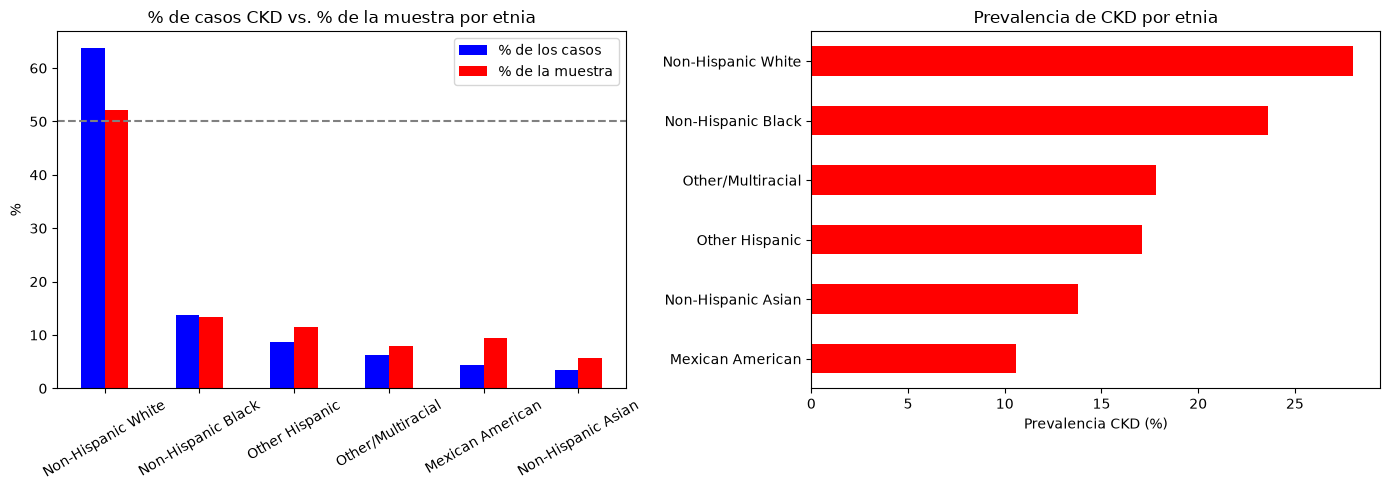

In [99]:
casos = df[df["ckd_present"] == 1]
cc = casos["ethnicity"].value_counts()
cm = df["ethnicity"].value_counts()
tabla = pd.DataFrame({
    "casos": cc,
    "% de los casos": (cc / cc.sum() * 100).round(1),
    "n muestra": cm,
    "% de la muestra": (cm / cm.sum() * 100).round(1),
    "prevalencia CKD %": (cc / cm * 100).round(1),
}).sort_values("casos", ascending=False)
print("\n", tabla)

# ---------- 4. Test de la hipótesis: ¿proporción NH-White > 0,50? ----------
k, n = cc["Non-Hispanic White"], len(casos)
res = stats.binomtest(k, n, 0.5, alternative="greater")
ic = stats.binomtest(k, n).proportion_ci(0.95)
print(f"\nNH-White: {k}/{n} = {k/n*100:.1f}% | IC95% {ic.low*100:.1f}-{ic.high*100:.1f}% | p = {res.pvalue:.3g}")
print("¿Se sostiene la hipótesis?", "SÍ" if (res.pvalue < 0.05 and k / n > 0.5) else "NO")

cc = casos["ethnicity"].value_counts()
cm = df["ethnicity"].value_counts()
tabla = pd.DataFrame({
    "casos": cc,
    "% de los casos": (cc / cc.sum() * 100).round(1),
    "n muestra": cm,
    "% de la muestra": (cm / cm.sum() * 100).round(1),
    "prevalencia CKD %": (cc / cm * 100).round(1),
}).sort_values("casos", ascending=False)
print("\n", tabla)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

tabla[["% de los casos", "% de la muestra"]].plot.bar(ax=ax[0], color=["#0000ff", "#FF0000"])
ax[0].axhline(50, ls="--", c="gray")
ax[0].set_title("% de casos CKD vs. % de la muestra por etnia")
ax[0].set_ylabel("%"); ax[0].set_xlabel("")
ax[0].tick_params(axis="x", rotation=30)

tabla["prevalencia CKD %"].sort_values().plot.barh(ax=ax[1], color="#FF0000")
ax[1].set_title("Prevalencia de CKD por etnia"); ax[1].set_xlabel("Prevalencia CKD (%)"); ax[1].set_ylabel("")

plt.tight_layout()
plt.show

Por el planteo de hipotesis no se busca porcentaje de cada etnia sino quienes son los que tienen mayoria de los ckd de nuestro dataframe, 
siendo la etnia non-hispanic white el 52.1% de la muestra por ende solo por probabilidad la mayoría de los casos de CKF identificados 
corresponderian a blancos no-hispánicos.
para un futuro analisis la hipotesis deberia ser planteada desde el punto de vista de proporcion de casos por etnia

# HIPOTESIS BIVARIADA 3: La presión arterial es un factor de riesgo del CKF.


# HIPOTESIS MULTIVARIADA 2

Participantes incluidos: 5436
Varianza explicada (%): [28.1 22.3 18.5 12.7  8.8  5.8  4. ]
Acumulada (%): [ 28.1  50.3  68.8  81.5  90.3  96.  100. ]
                      PC1   PC2   PC3   PC4   PC5   PC6   PC7
age                  0.51 -0.13 -0.08  0.58  0.30 -0.39 -0.37
bmi                  0.16  0.26 -0.60 -0.47  0.52 -0.20  0.15
bp_systolic          0.51  0.36  0.31  0.12 -0.10 -0.08  0.69
bp_diastolic         0.33  0.58  0.22 -0.25 -0.10  0.30 -0.59
serum_creatinine     0.37 -0.42  0.06 -0.53 -0.45 -0.43 -0.10
blood_urea_nitrogen  0.43 -0.51 -0.00 -0.11  0.27  0.69  0.08
albumin_serum       -0.17 -0.10  0.70 -0.26  0.59 -0.23 -0.04


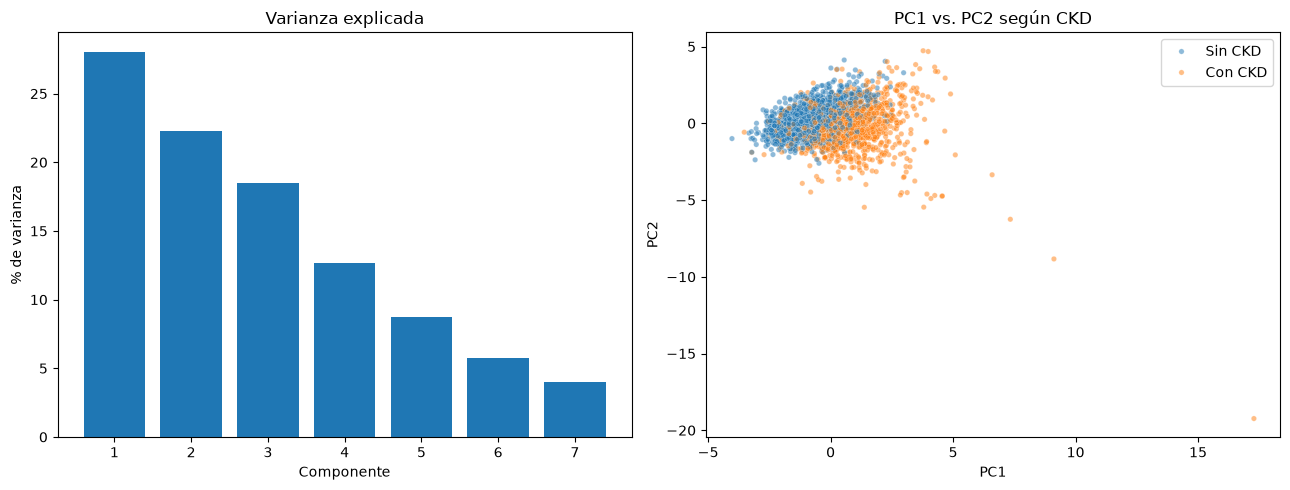

In [100]:
cols = [
    "age",
    "bmi",
    "bp_systolic",
    "bp_diastolic",
    "serum_creatinine",
    "blood_urea_nitrogen",
    "albumin_serum",
    #"albumin_creatinine_ratio",
    #"egfr"
]

# Filtrar adultos con datos completos
d = df[df["age"] >= 18][cols + ["ckd_present", "ckd_stage"]].dropna().copy()

# Excluir clasificaciones desconocidas
d = d[d["ckd_stage"] != "Unknown"]

print("Participantes incluidos:", len(d))

# Estandarizar variables
X = StandardScaler().fit_transform(d[cols])

# PCA
pca = PCA().fit(X)
Z = pca.transform(X)

print("Varianza explicada (%):",
      (pca.explained_variance_ratio_ * 100).round(1))

print("Acumulada (%):",
      (pca.explained_variance_ratio_.cumsum() * 100).round(1))

print(pd.DataFrame(
    pca.components_.T,
    index=cols,
    columns=[f"PC{i+1}" for i in range(len(cols))]
).round(2))

# Gráficos
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

ax[0].bar(
    range(1, len(cols) + 1),
    pca.explained_variance_ratio_ * 100
)
ax[0].set_xlabel("Componente")
ax[0].set_ylabel("% de varianza")
ax[0].set_title("Varianza explicada")

# Seleccionar muestra para visualizar
idx = np.random.default_rng(0).choice(
    len(d), min(2500, len(d)), replace=False
)

sns.scatterplot(
    x=Z[idx, 0],
    y=Z[idx, 1],
    hue=np.where(
        d["ckd_present"].to_numpy()[idx] == 1,
        "Con CKD",
        "Sin CKD"
    ),
    alpha=0.5,
    s=15,
    ax=ax[1]
)

ax[1].set_xlabel("PC1")
ax[1].set_ylabel("PC2")
ax[1].set_title("PC1 vs. PC2 según CKD")

plt.tight_layout()
plt.show()
